# Lab 14: MCMC for Feynman Path Integral Tutorial

In the lecture we saw some results from S.Mittal et al, and we will try to reproduce them in the lab today. The Markov chain Monte Carlo (MCMC) method can be used to evaluate the
discrete imaginary-time path integral (an alternative formulation to the path integral) of a quantum harmonic oscillator system with "Euclidean Lagragian" $L_E(x(\tau))=\frac{m}{2}(\frac{dx}{d\tau})^2 +V(x(\tau))$, and we can obtain a histogram of the probability density by summing up the number of times a particle is in a bin. 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tqdm

Analytic solution of the Schodinger equation to the ground state wavefunction of a quantum harmonic oscillator is given by: $\psi(x)=(\frac{m\omega}{\pi\hbar})^{1/4} \exp{(-\frac{m\omega}{2\hbar} x^2)}$.

A different approach to solving the Schodinger equation is by evaluating the imaginary-time path integral for this system using the Markov chain Monte Carlo (MCMC) method.


The path is assigned along a time lattice to $N_{xbins} =100$ spatial bins ranging in $[-4,4]$ with width $\Delta x$. Choose time lattice with $N_{\tau} = 30$ time increments $\delta\tau$ with lattice points $x_n = n\delta \tau$ for $n = 0,1,2,...,N_{\tau}$, over $n_{sweeps} = 20,000$, hitsize $h = 0.1$, and set $m=\hbar=1=\omega$. Periodic boundary condition is imposed on the lattice. 

All random numbers come from one generator, `rng`, seeded with `SEED`, so the run can be repeated exactly. Assignment 3 asks you to seed from your own fixed integer (such as your TSN) and report it.


In [2]:
SEED = 142  # in Assignment 3, use your own fixed integer, such as your TSN
rng = np.random.default_rng(SEED)

SWEEPS = 20_000
H = 1
OMEGA = 1
M = 1
TAU = 30
DELTATAU = 1
NTAU = int(TAU/DELTATAU)
HITSIZE = 0.1

XLOW = -4
XHIGH = 4
NXBINS = 100
DELTAX = (XHIGH - XLOW) / NXBINS
HITSIZE = 0.1
prob_histogram = np.zeros(NXBINS)
x2_values = np.zeros(SWEEPS)  # (1/N_tau) sum_i x_i^2 after every sweep
acceptance = np.zeros(SWEEPS)  # fraction of accepted updates in every sweep
x_bins = np.linspace(XLOW, XHIGH, NXBINS + 1)

x_path = np.zeros(NTAU)
## analytical solution
psi_analytical = (M*OMEGA/(np.pi*H))**0.25*np.exp(-M*OMEGA*x_bins**2/2/H)

We begin with an initial path $x_{path}$, which may be an array of random numbers (‘hot’ start) or zeros (‘cold’ start), and we use the ‘cold’ start for now. This path is updated by applying the Metropolis–Hastings algorithm to each element $x_i$ of the path in random order, called a ‘sweep’. There are two steps in the updating process:
- Generate a uniform random number $u \in [-h, h]$ (where h is called the hitsize)
- Propose the new value $x_i'=x_i +u$ of the path element and calculate the resulting change $\Delta S$ in the action.
If $\Delta S \leq 0$, accept the new path element.
If $\Delta S > 0$, accept with probability $exp(-\Delta S/\hbar)$.

For better performance, we can play with the parameters DELTATAU, HITSIZE, SWEEPS, etc, and we can also add "thinning" where only every Nth sweep is saved. For example:
- if we choose a smaller time step $\delta\tau = 0.1$, we end up with better energy approximation to the ground state; 
- if the hitsize we choose is too large, few changes will be accepted; too small and the exploration of phase space will be slow. How should we choose the hit size wisely?

The action is $S(\{x_k\})=\delta\tau\sum_{i=0}^{N_{\tau}-1}[\frac{m}{2}(\frac{x_{i+1}-x_i}{\delta \tau})^2 +V(x_i)]$, with $x_{N_\tau} \equiv x_0$ and $V(x) = \frac{m\omega^2}{2}x^2$.
This evaluates $V$ at the left end of each time step, as in Mittal et al. and Assignment 3. Lecture 13 evaluates it at the midpoint $(x_i+x_{i+1})/2$ instead; both have the same $\delta\tau \to 0$ limit, but for the harmonic oscillator the midpoint form happens to give the exact ground-state $\langle x^2 \rangle$ at any $\delta\tau$, which would hide the discretization error we want to study.
Note that one sweep produces the next path. Each path is determined only by
the immediately preceding path, so the complete sequence of paths forms a Markov chain,
but the paths are correlated.

In [3]:
def vary_path(x_current):
    x_prime = x_current + rng.random() * 2 * HITSIZE - HITSIZE
    while x_prime > XHIGH or x_prime < XLOW:
        x_prime = x_current + rng.random() * 2 * HITSIZE - HITSIZE
    return x_prime

def action(x_left, x_right):
    K = 0.5 * M * (((x_right - x_left))**2) / DELTATAU
    V = 0.5 * M * DELTATAU * (OMEGA**2) * x_left**2
    return K + V

def total_action(x_path):
    path_action = 0
    for i in range(-1, NTAU-1):
        path_action += action(x_path[i], x_path[i+1])
    return path_action

def delta_action(x_path, x_prime, i):
    x_left = x_path[i-1]
    x_right = x_path[i+1] if i < NTAU-1 else x_path[0] #PBC.
    daction = action(x_left, x_prime) + action(x_prime, x_right) 
    daction -= action(x_left, x_path[i]) + action(x_path[i], x_right) #compute the resulting change from u in delta S.
    return daction

def MCMC(x_path, prob_histogram):
    accepted = 0
    for i in range(NTAU):
        x_prime = vary_path(x_path[i])
        daction = delta_action(x_path, x_prime, i)
        if daction <= 0:            
            x_path[i] = x_prime
            accepted += 1
        else:        
            prob = np.exp(-daction)
            if rng.random() < prob:
                x_path[i] = x_prime
                accepted += 1
    hist, _ = np.histogram(x_path, bins=x_bins)
    prob_histogram += hist
    return np.mean(x_path**2), accepted / NTAU

In [4]:
for k in tqdm.tqdm(range(SWEEPS)):
    x2_values[k], acceptance[k] = MCMC(x_path, prob_histogram)
print(f"acceptance rate: {acceptance.mean():.2f}")

100%|██████████| 20000/20000 [00:01<00:00, 16018.54it/s]


acceptance rate: 0.97


Finally we get the histogram of the probability density by summing up the number of times a particle is in a bin, and compare it to the analytical solution. The MCMC histogram is close to the analytical curve but slightly narrower: with $m=\hbar=\omega=1$ and a long path, the discretized action gives $\langle x^2 \rangle = 1/\sqrt{4+\delta\tau^2}$, which is $0.447$ at $\delta\tau = 1$ instead of $1/2$. Try $\delta\tau = 0.1$ to see it converge, as in Fig. 5 of Mittal et al.

The array `x2_values` holds $\frac{1}{N_\tau}\sum_i x_i^2$ after every sweep (for the harmonic oscillator, $\langle E\rangle = m\omega^2\langle x^2\rangle$ by the virial theorem), and `acceptance` holds the fraction of updates accepted in each sweep. The second plot below shows the burn-in from the cold start. Use this time series to measure the autocorrelation function, the integrated autocorrelation time $\tau_\mathrm{int}$, and the blocking error bar from Lab 12, and tune the hit size so that 40–60% of updates are accepted.

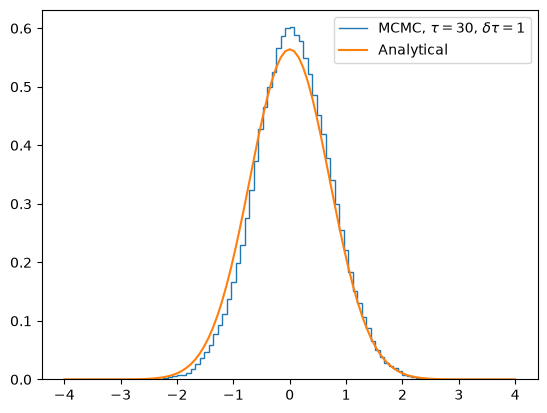

In [5]:
plt.figure()
plt.stairs(prob_histogram/np.sum(prob_histogram*DELTAX), x_bins, label=f"MCMC, $\\tau = {TAU}$, $\\delta\\tau={DELTATAU}$")
plt.plot(x_bins, psi_analytical*psi_analytical.conjugate(), label="Analytical")
plt.legend()
plt.show()

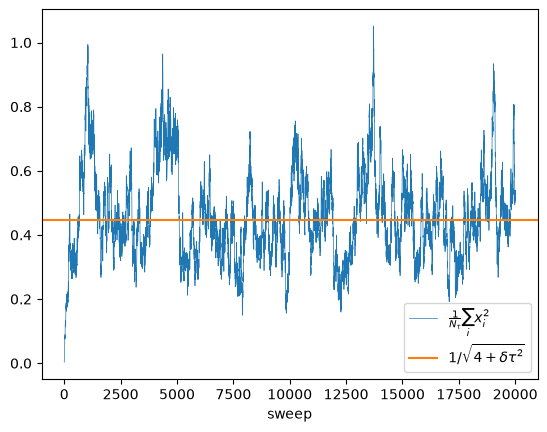

In [6]:
plt.figure()
plt.plot(x2_values, lw=0.5, label=r"$\frac{1}{N_\tau}\sum_i x_i^2$")
plt.axhline(1/np.sqrt(4 + DELTATAU**2), color="C1", label=r"$1/\sqrt{4+\delta\tau^2}$")
plt.xlabel("sweep")
plt.legend()
plt.show()